# 07 — Tuned Random Forest on three-day data

Focused retune of the notebook 05 winner (RF + Set A) on the full three-day dataset. The June 14 deliverable used two-day data and reported LOSO macro-F1 = 0.624 ± 0.061. This notebook produces the updated three-day headline number and the confusion matrix that drives the design of notebook 08 (hierarchical model).

**Scope.** One model family (Random Forest), one feature set (Set A, the LOSO winner from notebook 05), one small grid (6 hyperparameter combinations). The grid expands depth to test whether unconstrained trees help the bus, metro, tram cluster.

**Evaluation.** Three internal levels:
- E0 (random window split): 5 stratified folds. Optimistic, kept as the within-distribution upper bound.
- E1 (session split): 5 folds with `StratifiedGroupKFold` over session_id. Generalization to new recordings from known users.
- E2 (leave-one-subject-out): 3 folds. Generalization to unseen users. The headline.

Nested CV inside each outer fold uses session-grouped 3-fold CV on the training data for hyperparameter selection.

**Outputs.**
- `reports/results/rf_three_days_table.csv`
- `reports/results/rf_three_days_per_fold.csv`
- `reports/results/rf_three_days_per_class.csv`
- `reports/results/rf_three_days_importance.csv`
- `reports/results/rf_three_days_best_pipeline.pkl`
- `reports/figures/cm_loso_rf_three_days.png`

## 1. Imports and configuration

In [1]:
import json
import pickle
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    StratifiedKFold, GroupKFold, StratifiedGroupKFold,
    LeaveOneGroupOut, GridSearchCV,
)
from sklearn.metrics import f1_score, confusion_matrix, classification_report

warnings.filterwarnings('ignore')

PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import features as F

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
FEATURES_DIR  = PROJECT_ROOT / 'reports' / 'features'
RESULTS_DIR   = PROJECT_ROOT / 'reports' / 'results'
FIGURES_DIR   = PROJECT_ROOT / 'reports' / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Two-day baseline from notebook 05, for comparison in the results table
TWO_DAY_LOSO_MEAN = 0.624
TWO_DAY_LOSO_STD  = 0.061

## 2. Load three-day features

Load the feature CSV produced by the refactored notebook 04 after day 3 was added. Sanity-check that the data covers three days per participant and that the window count grew roughly 50 percent relative to the two-day version.

In [2]:
features_df = pd.read_csv(PROCESSED_DIR / 'features_common_no_baro.csv')
inventory = pd.read_csv(FEATURES_DIR / 'feature_inventory.csv')

meta_cols = ['session_id', 'participant', 'mode', 'mode_id', 'day',
             'window_index', 'window_start_s', 'window_end_s', 'flagged_frac']

print(f'Total windows: {len(features_df)}')
print(f'Participants:  {sorted(features_df["participant"].unique())}')
print(f'Days:          {sorted(features_df["day"].unique())}')
print(f'Modes:         {sorted(features_df["mode"].unique())}')
print()
print('Windows per participant x day:')
print(features_df.groupby(['participant', 'day']).size()
      .unstack(fill_value=0).to_string())
print()
print('Windows per participant x mode:')
print(features_df.groupby(['participant', 'mode']).size()
      .unstack(fill_value=0).to_string())

# Sanity: should have day1, day2, day3 for all participants
n_days = features_df['day'].nunique()
assert n_days == 3, f'Expected 3 days, found {n_days}. Re-run notebook 04 on three-day interim data.'

Total windows: 14513
Participants:  ['athina', 'babis', 'xiomara']
Days:          ['day1', 'day2', 'day3']
Modes:         ['bus', 'cycling', 'metro', 'stationary', 'tram', 'walking']

Windows per participant x day:
day          day1  day2  day3
participant                  
athina       1564  1598  1554
babis        1568  1668  1683
xiomara      1753  1570  1555

Windows per participant x mode:
mode         bus  cycling  metro  stationary  tram  walking
participant                                                
athina       881      727    906         703   810      689
babis        828      852    840         841   835      723
xiomara      614      916    803         967   810      768


## 3. Define Set A and the three CV splitters

Set A is the LOSO winner from notebook 05: time-domain basic statistics plus slope. Defined here from the family inventory so it stays consistent with the rest of the pipeline.

In [3]:
feature_set_a = inventory.loc[
    inventory['family'].isin(['time_domain_basic', 'slope']),
    'feature'
].tolist()

feature_set_a = [c for c in feature_set_a if c in features_df.columns]
print(f'Set A: {len(feature_set_a)} features')

X = features_df[feature_set_a].values
y = features_df['mode_id'].values
groups_session = features_df['session_id'].values
groups_participant = features_df['participant'].values

print(f'X shape: {X.shape}')
print(f'Sessions:     {len(np.unique(groups_session))}')
print(f'Participants: {sorted(np.unique(groups_participant))}')

Set A: 80 features
X shape: (14513, 80)
Sessions:     54
Participants: ['athina', 'babis', 'xiomara']


In [4]:
def get_outer_splitter(level: str):
    if level == 'E0':
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    if level == 'E1':
        return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    if level == 'E2':
        return LeaveOneGroupOut()
    raise ValueError(level)


def get_outer_groups(level: str):
    if level == 'E0':
        return None
    if level == 'E1':
        return groups_session
    if level == 'E2':
        return groups_participant
    raise ValueError(level)


def get_inner_splitter():
    # Session-grouped 3-fold inside each outer training fold
    return GroupKFold(n_splits=3)


for level in ('E0', 'E1', 'E2'):
    outer = get_outer_splitter(level)
    g = get_outer_groups(level)
    n_folds = sum(1 for _ in outer.split(X, y, g))
    print(f'{level}: {n_folds} outer folds')

E0: 5 outer folds
E1: 5 outer folds
E2: 3 outer folds


## 4. Hyperparameter grid

Six combinations. Three tree counts and two depths. The unconstrained depth (`max_depth=None`) is the new option; notebook 05 used `max_depth=20`. The motivation is the bus, metro, tram confusion in the two-day result, which deeper trees might address by carving finer decision regions.

We do not tune `min_samples_leaf` because notebook 05's nested CV consistently picked 1. Holding it fixed reduces the grid without losing relevant variation.

In [5]:
def build_rf():
    clf = RandomForestClassifier(
        n_jobs=-1, random_state=RANDOM_STATE,
        min_samples_leaf=1,
    )
    grid = {
        'n_estimators': [200, 400, 600],
        'max_depth':    [20, None],
    }
    return clf, grid


_, grid = build_rf()
n_combos = np.prod([len(v) for v in grid.values()])
print(f'Grid size: {n_combos} combinations')
print(f'Grid: {grid}')

Grid size: 6 combinations
Grid: {'n_estimators': [200, 400, 600], 'max_depth': [20, None]}


## 5. Nested cross-validation

For each outer fold, an inner session-grouped GridSearchCV selects the best hyperparameters on macro-F1, then refits on the full training fold and predicts once on the held-out test fold. Runtime should be five to fifteen minutes total.

In [6]:
def run_nested_cv(X, y, groups_outer, outer_splitter, inner_splitter):
    results = []
    for fold_idx, (train_idx, test_idx) in enumerate(
        outer_splitter.split(X, y, groups=groups_outer)
    ):
        X_tr, X_te = X[train_idx], X[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]
        inner_groups = groups_session[train_idx]

        estimator, grid = build_rf()
        gs = GridSearchCV(
            estimator=estimator,
            param_grid=grid,
            cv=inner_splitter,
            scoring='f1_macro',
            n_jobs=1,  # RF already uses all cores
            refit=True,
        )
        gs.fit(X_tr, y_tr, groups=inner_groups)
        y_pred = gs.best_estimator_.predict(X_te)
        macro_f1 = f1_score(y_te, y_pred, average='macro')

        held_out = (
            '_'.join(sorted(set(map(str, groups_outer[test_idx]))))
            if groups_outer is not None else f'fold_{fold_idx}'
        )
        results.append({
            'fold':        fold_idx,
            'held_out':    held_out,
            'macro_f1':    float(macro_f1),
            'best_params': gs.best_params_,
            'y_true':      y_te,
            'y_pred':      y_pred,
            'fitted_model': gs.best_estimator_,
        })
    return results


all_results = {}   # level -> list of per-fold dicts

for level in ('E0', 'E1', 'E2'):
    t0 = time.time()
    outer = get_outer_splitter(level)
    outer_groups = get_outer_groups(level)
    inner = get_inner_splitter()
    folds = run_nested_cv(X, y, outer_groups, outer, inner)
    all_results[level] = folds
    elapsed = time.time() - t0
    f1s = np.array([r['macro_f1'] for r in folds])
    print(f'{level} | macro-F1 = {f1s.mean():.3f} +/- {f1s.std():.3f} | {elapsed:.0f}s')

E0 | macro-F1 = 0.899 +/- 0.004 | 162s
E1 | macro-F1 = 0.636 +/- 0.030 | 176s
E2 | macro-F1 = 0.568 +/- 0.064 | 125s


## 6. Per-fold results

In [7]:
rows = []
for level, folds in all_results.items():
    for r in folds:
        rows.append({
            'level':       level,
            'fold':        r['fold'],
            'held_out':    r['held_out'],
            'macro_f1':    r['macro_f1'],
            'best_params': json.dumps(r['best_params']),
        })
per_fold = pd.DataFrame(rows)
per_fold.to_csv(RESULTS_DIR / 'rf_three_days_per_fold.csv', index=False)
print(per_fold.to_string(index=False))

level  fold                                                                                                                                                                                                                              held_out  macro_f1                              best_params
   E0     0                                                                                                                                                                                                                                fold_0  0.902946   {"max_depth": 20, "n_estimators": 600}
   E0     1                                                                                                                                                                                                                                fold_1  0.892450 {"max_depth": null, "n_estimators": 600}
   E0     2                                                                                                              

## 7. Headline table

Aggregate per-fold results and compute drop columns against the two-day baseline from notebook 05.

In [8]:
rows = []
for level, folds in all_results.items():
    f1s = np.array([r['macro_f1'] for r in folds])
    rows.append({
        'level':           level,
        'macro_f1_mean':   float(f1s.mean()),
        'macro_f1_std':    float(f1s.std()),
        'n_folds':         len(folds),
    })
table = pd.DataFrame(rows)

# Add E0 to E1 and E1 to E2 drops
lookup = table.set_index('level')['macro_f1_mean'].to_dict()
table['drop_from_E0'] = table['level'].map(lambda l: lookup['E0'] - lookup[l])

table.to_csv(RESULTS_DIR / 'rf_three_days_table.csv', index=False)

print('Headline (RF + Set A, three-day data):')
print(table.round(3).to_string(index=False))
print()
print(f'Two-day LOSO baseline (notebook 05):  {TWO_DAY_LOSO_MEAN:.3f} +/- {TWO_DAY_LOSO_STD:.3f}')
delta = lookup['E2'] - TWO_DAY_LOSO_MEAN
noise_floor = max(table.loc[table['level'] == 'E2', 'macro_f1_std'].iloc[0],
                  TWO_DAY_LOSO_STD)
verdict = ('improves over two-day' if delta > noise_floor else
           'matches two-day (within noise)' if abs(delta) <= noise_floor else
           'degrades from two-day')
print(f'Three-day LOSO {verdict} (delta = {delta:+.3f}, noise floor = {noise_floor:.3f})')

Headline (RF + Set A, three-day data):
level  macro_f1_mean  macro_f1_std  n_folds  drop_from_E0
   E0          0.899         0.004        5         0.000
   E1          0.636         0.030        5         0.263
   E2          0.568         0.064        3         0.331

Two-day LOSO baseline (notebook 05):  0.624 +/- 0.061
Three-day LOSO matches two-day (within noise) (delta = -0.056, noise floor = 0.064)


## 8. Winning hyperparameters

Look at which combination won most often across the LOSO folds. We will use the majority pick for the saved pipeline.

In [9]:
from collections import Counter

loso_folds = all_results['E2']
param_picks = [json.dumps(r['best_params'], sort_keys=True) for r in loso_folds]
counter = Counter(param_picks)

print('LOSO hyperparameter selections:')
for params_json, count in counter.most_common():
    print(f'  {count}x  {params_json}')

best_params = json.loads(counter.most_common(1)[0][0])
print(f'\nMajority pick: {best_params}')

LOSO hyperparameter selections:
  1x  {"max_depth": null, "n_estimators": 200}
  1x  {"max_depth": 20, "n_estimators": 200}
  1x  {"max_depth": null, "n_estimators": 400}

Majority pick: {'max_depth': None, 'n_estimators': 200}


## 9. Confusion matrix on LOSO

Concatenate held-out predictions across the three LOSO folds. This matrix drives the level structure of notebook 08.

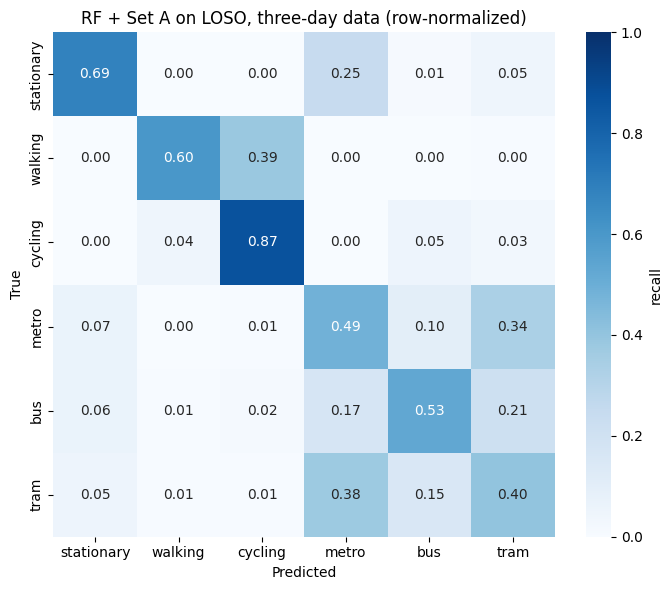

Saved: C:\Projects\this project-transport-mode\reports\figures\cm_loso_rf_three_days.png


In [10]:
y_true_all = np.concatenate([r['y_true'] for r in loso_folds])
y_pred_all = np.concatenate([r['y_pred'] for r in loso_folds])

cm = confusion_matrix(y_true_all, y_pred_all, labels=list(range(len(F.MODES))))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm_norm, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=F.MODES, yticklabels=F.MODES, ax=ax,
    cbar_kws={'label': 'recall'}, vmin=0, vmax=1,
)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('RF + Set A on LOSO, three-day data (row-normalized)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'cm_loso_rf_three_days.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f'Saved: {FIGURES_DIR / "cm_loso_rf_three_days.png"}')

## 10. Per-class F1 breakdown

Per-mode F1 for E2 (and E1 for comparison). Saved to CSV for the report and as input to the hierarchical design in notebook 08.

In [11]:
rows = []
for level in ('E1', 'E2'):
    folds = all_results[level]
    y_true = np.concatenate([r['y_true'] for r in folds])
    y_pred = np.concatenate([r['y_pred'] for r in folds])
    f1_per_class = f1_score(
        y_true, y_pred, labels=list(range(len(F.MODES))), average=None
    )
    row = {'level': level}
    for cls_id, mode in enumerate(F.MODES):
        row[f'f1_{mode}'] = float(f1_per_class[cls_id])
    rows.append(row)

per_class = pd.DataFrame(rows)
per_class.to_csv(RESULTS_DIR / 'rf_three_days_per_class.csv', index=False)
print('Per-class F1 (three-day, RF + Set A):')
print(per_class.round(3).to_string(index=False))

print()
print('Classification report on LOSO:')
print(classification_report(
    y_true_all, y_pred_all, target_names=F.MODES, digits=3,
))

Per-class F1 (three-day, RF + Set A):
level  f1_stationary  f1_walking  f1_cycling  f1_metro  f1_bus  f1_tram
   E1          0.692       0.958       0.952     0.467   0.521    0.290
   E2          0.736       0.721       0.778     0.432   0.563    0.394

Classification report on LOSO:
              precision    recall  f1-score   support

  stationary      0.793     0.687     0.736      2511
     walking      0.898     0.602     0.721      2180
     cycling      0.704     0.869     0.778      2495
       metro      0.389     0.486     0.432      2549
         bus      0.601     0.530     0.563      2323
        tram      0.385     0.402     0.394      2455

    accuracy                          0.597     14513
   macro avg      0.628     0.596     0.604     14513
weighted avg      0.623     0.597     0.602     14513



## 11. Feature importance

Mean and standard deviation of RF importance across the LOSO folds. Useful for the report and as a check that the three-day data did not shift which features matter.

In [12]:
importances = np.stack([f['fitted_model'].feature_importances_ for f in loso_folds])
imp_df = pd.DataFrame({
    'feature':         feature_set_a,
    'importance_mean': importances.mean(axis=0),
    'importance_std':  importances.std(axis=0),
})
imp_df = imp_df.merge(inventory, on='feature', how='left')
imp_df = imp_df.sort_values('importance_mean', ascending=False).reset_index(drop=True)
imp_df.to_csv(RESULTS_DIR / 'rf_three_days_importance.csv', index=False)

print('Top 20 features:')
print(imp_df.head(20)[['feature', 'family', 'importance_mean', 'importance_std']]
      .round(4).to_string(index=False))

print()
print('Importance summed by family:')
fam_sum = (imp_df.groupby('family')['importance_mean'].sum()
            .sort_values(ascending=False))
print(fam_sum.round(3).to_string())

Top 20 features:
          feature            family  importance_mean  importance_std
       lin_ay_iqr time_domain_basic           0.0414          0.0093
           gz_iqr time_domain_basic           0.0349          0.0049
           gz_std time_domain_basic           0.0346          0.0018
         gz_range time_domain_basic           0.0306          0.0026
linacc_mag_median time_domain_basic           0.0305          0.0088
       lin_ay_rms time_domain_basic           0.0302          0.0029
       lin_ay_std time_domain_basic           0.0279          0.0059
       lin_az_iqr time_domain_basic           0.0277          0.0085
  linacc_mag_mean time_domain_basic           0.0242          0.0028
           gz_rms time_domain_basic           0.0232          0.0047
   linacc_mag_rms time_domain_basic           0.0216          0.0010
       lin_az_std time_domain_basic           0.0210          0.0048
       lin_az_rms time_domain_basic           0.0208          0.0052
           gy_iqr

## 12. Save the best pipeline

Refit on all three-day data with the majority best hyperparameters from the LOSO folds. Saved for use in notebook 08 (hierarchical baseline) and notebook 09 (external validation).

In [13]:
final = RandomForestClassifier(
    n_jobs=-1, random_state=RANDOM_STATE, min_samples_leaf=1,
    **best_params,
)
final.fit(X, y)

artefact = {
    'model':         final,
    'feature_set':   'A',
    'feature_names': feature_set_a,
    'mode_to_id':    F.MODE_TO_ID,
    'best_params':   best_params,
    'loso_macro_f1': float(lookup['E2']),
    'loso_macro_f1_std': float(table.loc[table['level'] == 'E2', 'macro_f1_std'].iloc[0]),
    'two_day_baseline': TWO_DAY_LOSO_MEAN,
}
with open(RESULTS_DIR / 'rf_three_days_best_pipeline.pkl', 'wb') as f:
    pickle.dump(artefact, f)
print(f'Saved: {RESULTS_DIR / "rf_three_days_best_pipeline.pkl"}')

Saved: C:\Projects\this project-transport-mode\reports\results\rf_three_days_best_pipeline.pkl


## 13. Summary

What this notebook produced.

1. `rf_three_days_table.csv`: the three-day E0, E1, E2 macro-F1 numbers with comparison to the two-day baseline.
2. `rf_three_days_per_fold.csv`: per-fold details for the noise discussion in the report.
3. `rf_three_days_per_class.csv`: per-mode F1 for E1 and E2.
4. `cm_loso_rf_three_days.png`: the confusion matrix that drives the hierarchical level design in notebook 08.
5. `rf_three_days_importance.csv`: feature importance ranking with family annotations.
6. `rf_three_days_best_pipeline.pkl`: the refit model for notebooks 08 and 09.

Next: notebook 08 uses the confusion matrix from step 4 to commit to a hierarchical level structure, then trains classifiers at each level and compares the cascade against the flat RF baseline produced here.